# 1. Dataset description

`presented dataset contains International 10/20 system EEG recordings from subjects under mental cognitive workload (performing mental serial subtraction) and the corresponding reference background EEGs. Based on the subtraction task performance (number of subtractions and accuracy of the result), the subjects were divided into good counters and bad counters (for whom the mental task required excessive efforts). The data was recorded from 36 healthy volunteers of matched age, all of whom are students of Educational and Scientific Centre “Institute of Biology and Medicine”, National Taras Shevchenko University of Kyiv (Ukraine); the recordings are available through Physiobank platform. The dataset can be used by the neuroscience research community studying brain dynamics during cognitive workload.` [[1]](https://www.mdpi.com/2306-5729/4/1/14)


In [1]:
!pip install mne

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 1.1 MB/s eta 0:00:0000:0100:01
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 1.8 MB/s eta 0:00:0000:0100:010m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 2.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 3.5 MB/s eta 0:00:0000:0100:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 9.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 8.8 MB/s eta 0:00:00a 0:00:01m
Using cached pyparsing-3.3.2-py3-none-any.whl (122 kB)


In [ ]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import mne

mne.set_log_level("WARNING")

DATA_DIR = Path("datasets/physionet.org/files/eegmat/1.0.0")

: 

# Opis metadanych `subject-info.csv` (EEGMAT Dataset)

**Źródło:** _Zyma I. et al. (2019), "Electroencephalograms during Mental Arithmetic Task Performance", Data / PhysioNet_

---

### Opis kolumn

- **`Subject`**: Unikalny identyfikator badanego (np. `Subject00`, `Subject01`).
- **`Age`**: Wiek uczestnika badania wyrażony w latach.
- **`Gender`**: Płeć uczestnika:
- `F` – Kobieta (_Female_)
- `M` – Mężczyzna (_Male_)

- **`Recording date`**: Data przeprowadzenia sesji nagraniowej EEG.
- **`Number of subtractions`**:
- **Opis**: Wskaźnik wydajności w zadaniu arytmetycznym (seryjne odejmowanie liczby 2-cyfrowej od liczby 4-cyfrowej w pamięci).
- **Wzór**: $(\text{Liczba początkowa} - \text{Wynik końcowy}) / \text{Odejmowana wartość}$
- **Format (`float`)**: Przyjmuje wartości ułamkowe, ponieważ uwzględnia błędy rachunkowe popełnione przez badanego w trakcie zadania.

- **`Count quality`**:
- **Opis**: Klasyfikacja efektywności liczenia na podstawie całkowitej liczby wykonanych operacji i ich poprawności.
- **Wartości**:
- `1` / **`G`** (_Good quality_, 24 osoby) – wysoka wydajność obliczeniowa ($\text{średnio } 21 \text{ operacji / 4 min}$, $\text{SD} = 7.4$).
- `0` / **`B`** (_Bad quality_, 12 osób) – niska wydajność, wysoki wysiłek poznawczy ($\text{średnio } 7 \text{ operacji / 4 min}$, $\text{SD} = 3.6$).


In [ ]:
info = pd.read_csv(DATA_DIR / "subject-info.csv")
info

,Subject,Age,Gender,Recording year,Number of subtractions,Count quality
0,Subject00,21,F,2011,9.70,0
1,Subject01,18,F,2011,29.35,1
2,Subject02,19,F,2012,12.88,1
3,Subject03,17,F,2010,31.00,1
4,Subject04,17,F,2010,8.60,0
5,Subject05,16,F,2010,20.71,1
6,Subject06,18,M,2011,4.35,0
7,Subject07,18,F,2012,13.38,1
8,Subject08,26,M,2011,18.24,1
9,Subject09,16,F,2010,7.00,0


In [ ]:
raw = mne.io.read_raw_edf(DATA_DIR / "Subject00_1.edf", preload=True)
print(raw.info)
print("kanaly:", raw.ch_names)
print("fs:", raw.info["sfreq"], "Hz")
print("czas:", raw.times[-1], "s")

<Info | 8 non-empty values
 bads: []
 ch_names: EEG Fp1, EEG Fp2, EEG F3, EEG F4, EEG F7, EEG F8, EEG T3, EEG ...
 chs: 21 EEG
 custom_ref_applied: False
 highpass: 0.5 Hz
 lowpass: 45.0 Hz
 meas_date: 2011-01-01 00:00:00 UTC
 nchan: 21
 projs: []
 sfreq: 500.0 Hz
 subject_info: <subject_info | his_id: 0, sex: 1, last_name: Subject0, birthday: 1990-01-01>
>
kanaly: ['EEG Fp1', 'EEG Fp2', 'EEG F3', 'EEG F4', 'EEG F7', 'EEG F8', 'EEG T3', 'EEG T4', 'EEG C3', 'EEG C4', 'EEG T5', 'EEG T6', 'EEG P3', 'EEG P4', 'EEG O1', 'EEG O2', 'EEG Fz', 'EEG Cz', 'EEG Pz', 'EEG A2-A1', 'ECG ECG']
fs: 500.0 Hz
czas: 181.998 s


In [ ]:
# stary zapis 10-20 -> wspolczesny, potrzebny do standard_1020 i topomap
OLD2NEW = {"T3": "T7", "T4": "T8", "T5": "P7", "T6": "P8"}

def tidy(raw):
    raw.rename_channels({ch: ch.replace("EEG ", "").strip() for ch in raw.ch_names})
    remap = {}
    for ch in raw.ch_names:
        u = ch.upper()
        if "ECG" in u:
            remap[ch] = "ecg"
        elif "A1" in u or "A2" in u:   # referencja uszna, nie kanal skalpowy
            remap[ch] = "misc"
    if remap:
        raw.set_channel_types(remap)
    return raw

def set_montage(raw):
    raw.rename_channels({ch: OLD2NEW[ch] for ch in raw.ch_names if ch in OLD2NEW})
    raw.set_montage("standard_1020", match_case=False, on_missing="warn")
    return raw

In [6]:
def parse_fname(p):
    m = re.match(r"Subject(\d+)_(\d)\.edf", p.name)
    return int(m.group(1)), int(m.group(2))  # (numer badanego, stan: 1 lub 2)

def load_all(data_dir, preload=False):
    records = {}
    for p in sorted(data_dir.glob("Subject*.edf")):
        subj, state = parse_fname(p)
        records[(subj, state)] = mne.io.read_raw_edf(p, preload=preload)
    return records

records = load_all(DATA_DIR)
print("liczba nagran:", len(records))

liczba nagran: 72


In [7]:
def make_dataset(records, epoch_len=4.0):
    X, y, groups = [], [], []
    for (subj, state), raw in records.items():
        r = set_montage(tidy(raw.copy().load_data()))
        ep = mne.make_fixed_length_epochs(r, duration=epoch_len, preload=True, verbose=False)
        data = ep.get_data(picks="eeg")          # (n_epok, n_kanalow, n_probek)
        X.append(data)
        y.append(np.full(len(data), 0 if state == 1 else 1))  # 0 = spoczynek, 1 = zadanie
        groups.append(np.full(len(data), subj))
    return np.concatenate(X), np.concatenate(y), np.concatenate(groups)

X, y, groups = make_dataset(records)
print("X:", X.shape, "| y:", np.bincount(y), "| badani:", len(np.unique(groups)))

/tmp/ipykernel_679885/1308072036.py:14: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/tmp/ipykernel_679885/1308072036.py:14: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/tmp/ipykernel_679885/1308072036.py:14: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/tmp/ipykernel_679885/1308072036.py:14: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/tmp/ipykernel_679885/1308072036.py:14: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/tmp/ipykernel_679885/1308072036.py:14: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/tmp/ipykernel_679885/1308072036.py:14: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)

X: (2134, 19, 2000) | y: [1594  540] | badani: 36


/tmp/ipykernel_679885/1308072036.py:14: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


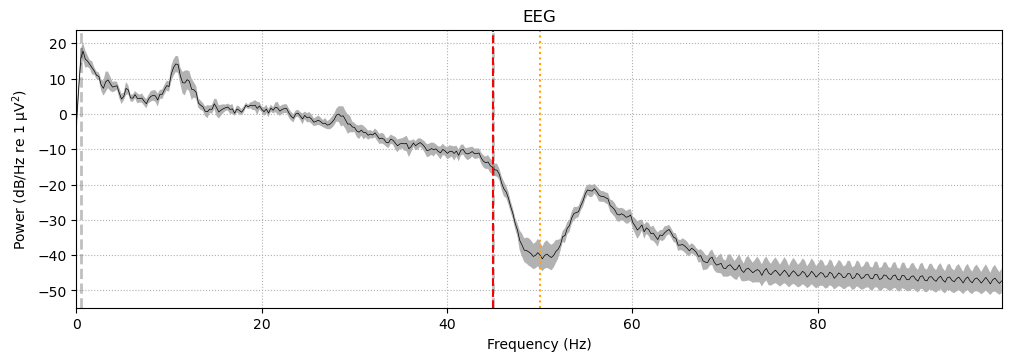

In [8]:
import matplotlib.pyplot as plt

raw_chk = set_montage(tidy(records[(0, 2)].copy().load_data()))
psd = raw_chk.compute_psd(picks="eeg", fmax=100)  # patrzymy powyzej 45, zeby zobaczyc odciecie
psd.plot(average=True)
plt.axvline(45, ls="--", c="r"); plt.axvline(50, ls=":", c="orange")
plt.show()

In [9]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import mne
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Konfiguracja ścieżki do danych
DATA_DIR = Path("datasets/physionet.org/files/eegmat/1.0.0")
mne.set_log_level("WARNING")

# Słownik zamiany starych nazw kanałów 10-20 na standardowe nazwy MNE
OLD2NEW = {"T3": "T7", "T4": "T8", "T5": "P7", "T6": "P8"}

def preprocess_raw(raw):
    """Czyszczenie nazw kanałów, ustawianie typów oraz montażu 10-20."""
    # Usunięcie prefiksu 'EEG ' z nazw
    raw.rename_channels({ch: ch.replace("EEG ", "").strip() for ch in raw.ch_names})
    
    # Przypisanie typów dla ECG oraz referencji usznych
    remap = {}
    for ch in raw.ch_names:
        u = ch.upper()
        if "ECG" in u:
            remap[ch] = "ecg"
        elif "A1" in u or "A2" in u:
            remap[ch] = "misc"
    if remap:
        raw.set_channel_types(remap)
        
    # Remapowanie dawnych nazw kanałów na standard 10-20
    raw.rename_channels({ch: OLD2NEW[ch] for ch in raw.ch_names if ch in OLD2NEW})
    raw.set_montage("standard_1020", match_case=False, on_missing="warn")
    
    # Podstawowe filtrowanie sygnału: pasmowoprzepustowy 1-40 Hz
    raw.filter(l_freq=1.0, h_freq=40.0, verbose=False)
    return raw

def extract_band_power(epochs):
    """
    Ekstrakcja gęstości widmowej mocy (PSD) dla podstawowych pasm EEG:
    Theta (4-8 Hz), Alpha (8-12 Hz), Beta (12-30 Hz).
    """
    bands = {
        'theta': (4, 8),
        'alpha': (8, 12),
        'beta': (12, 30)
    }
    
    # Obliczenie PSD metodą Welch'a
    psd = epochs.compute_psd(method='welch', fmin=1, fmax=40, verbose=False)
    psd_data, freqs = psd.get_data(return_freqs=True)  # Kształt: (n_epok, n_kanalow, n_czestotliwosci)
    
    features = []
    for fmin, fmax in bands.values():
        # Maska dla częstotliwości z danego pasma
        idx_band = np.logical_and(freqs >= fmin, freqs <= fmax)
        # Średnia moc w pasmie dla każdego kanału
        band_power = psd_data[:, :, idx_band].mean(axis=-1)  # Kształt: (n_epok, n_kanalow)
        features.append(band_power)
        
    # Połączenie cech ze wszystkich pasm w jeden wektor dla każdej epoki
    X_features = np.concatenate(features, axis=1)  # Kształt: (n_epok, n_kanalow * n_pasm)
    return X_features

# 2. Główna pętla wczytywania danych i generowania zbioru
def build_dataset(data_dir, epoch_duration=4.0):
    X_list, y_list, groups_list = [], [], []
    
    files = sorted(data_dir.glob("Subject*.edf"))
    print(f"Znaleziono {len(files)} plików EDF. Rozpoczynanie przetwarzania...")
    
    for filepath in files:
        # Ekstrakcja ID badanego i stanu (1 = spoczynek, 2 = zadanie)
        match = re.match(r"Subject(\d+)_(\d)\.edf", filepath.name)
        if not match:
            continue
        subj_id = int(match.group(1))
        state = int(match.group(2))
        
        # Wczytanie i preprocessing
        raw = mne.io.read_raw_edf(filepath, preload=True, verbose=False)
        raw = preprocess_raw(raw)
        
        # Podział sygnału na 4-sekundowe epoki
        epochs = mne.make_fixed_length_epochs(raw, duration=epoch_duration, preload=True, verbose=False)
        
        # Ekstrakcja cech z epok EEG
        features = extract_band_power(epochs)
        
        # Etykiety: 0 = Spoczynek (State 1), 1 = Zadanie matematyczne (State 2)
        labels = np.full(len(features), 0 if state == 1 else 1)
        groups = np.full(len(features), subj_id)
        
        X_list.append(features)
        y_list.append(labels)
        groups_list.append(groups)
        
    X = np.concatenate(X_list, axis=0)
    y = np.concatenate(y_list, axis=0)
    groups = np.concatenate(groups_list, axis=0)
    
    return X, y, groups

# 3. Przygotowanie danych
X, y, groups = build_dataset(DATA_DIR)
print(f"\nWygenerowano zbiór cech: X={X.shape}, y={y.shape}")
print(f"Liczba epok w stanie spoczynku (0): {np.sum(y == 0)}")
print(f"Liczba epok w stanie zadania (1): {np.sum(y == 1)}")

# 4. Walidacja krzyżowa z podziałem po badanych (GroupKFold)
# Zapobiega wyciekowi danych (data leakage) między epokami tego samego badanego
gkf = GroupKFold(n_splits=5)
clf = RandomForestClassifier(n_estimators=100, random_state=42)

accuracies = []
print("\nRozpoczynanie walidacji krzyżowej (Group 5-Fold CV)...")

for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups)):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    print(f"Fold {fold + 1} Accuracy: {acc:.4f}")

print(f"\nŚrednia dokładność (Mean Accuracy): {np.mean(accuracies):.4f}")

Znaleziono 72 plików EDF. Rozpoczynanie przetwarzania...


/tmp/ipykernel_679885/1888725948.py:31: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/tmp/ipykernel_679885/1888725948.py:31: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/tmp/ipykernel_679885/1888725948.py:31: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/tmp/ipykernel_679885/1888725948.py:31: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/tmp/ipykernel_679885/1888725948.py:31: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/tmp/ipykernel_679885/1888725948.py:31: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/tmp/ipykernel_679885/1888725948.py:31: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


Wygenerowano zbiór cech: X=(2134, 57), y=(2134,)
Liczba epok w stanie spoczynku (0): 1594
Liczba epok w stanie zadania (1): 540

Rozpoczynanie walidacji krzyżowej (Group 5-Fold CV)...
Fold 1 Accuracy: 0.7357
Fold 2 Accuracy: 0.7500
Fold 3 Accuracy: 0.7500
Fold 4 Accuracy: 0.7500
Fold 5 Accuracy: 0.7500

Średnia dokładność (Mean Accuracy): 0.7471


/tmp/ipykernel_679885/1308072036.py:14: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


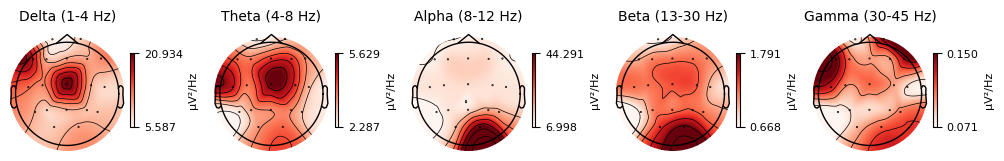

In [10]:
import matplotlib.pyplot as plt

# Pobranie przykładowego nagrania (Subject00, stan spoczynku = 1)
raw_sample = set_montage(tidy(records[(0, 1)].copy().load_data()))

# Obliczenie gęstości widmowej mocy (PSD)
psd = raw_sample.compute_psd(fmin=1, fmax=45)

# Rysowanie mapy topograficznej dla standardowych pasm częstotliwości
psd.plot_topomap(
    bands={
        'Delta (1-4 Hz)': (1, 4),
        'Theta (4-8 Hz)': (4, 8),
        'Alpha (8-12 Hz)': (8, 12),
        'Beta (13-30 Hz)': (13, 30),
        'Gamma (30-45 Hz)': (30, 45)
    },
    ch_type='eeg'
)
plt.show()

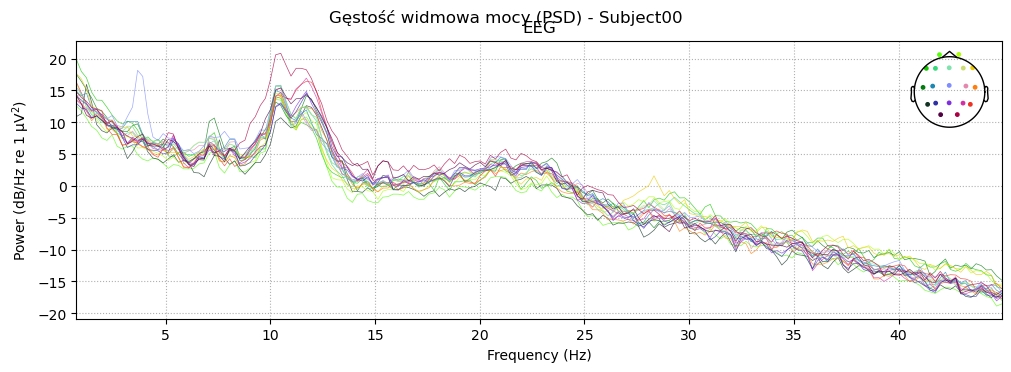

In [11]:
# Wykres widma mocy (PSD) dla wszystkich kanałów EEG
fig = raw_sample.compute_psd(fmin=0.5, fmax=45).plot(picks="eeg")
plt.suptitle("Gęstość widmowa mocy (PSD) - Subject00", y=1.02)
plt.show()

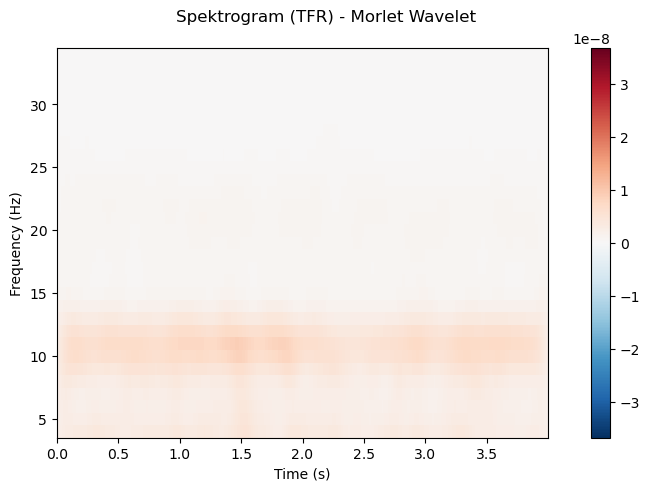

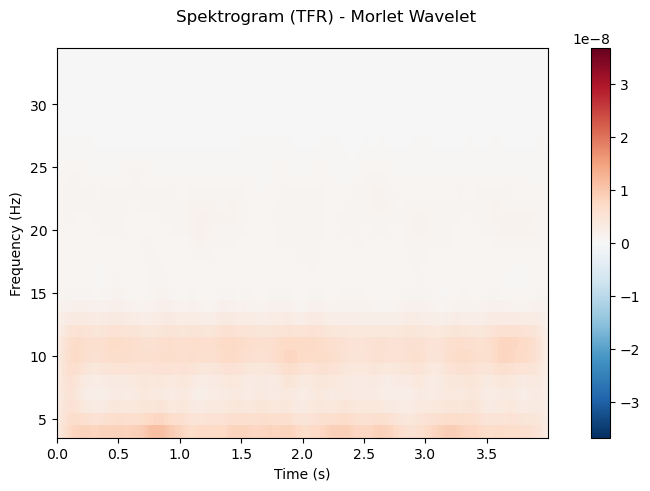

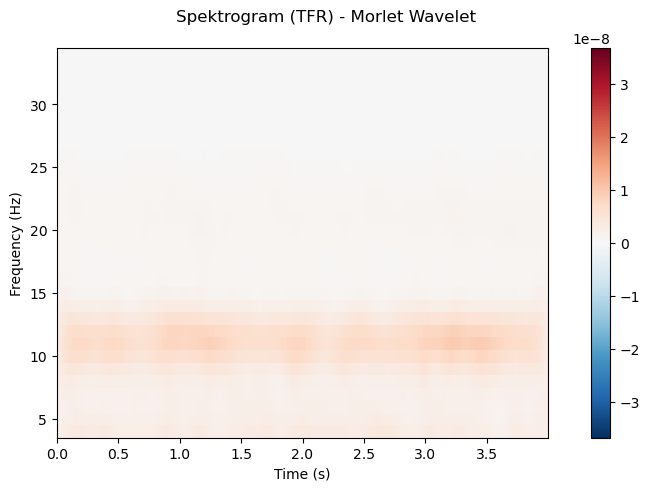

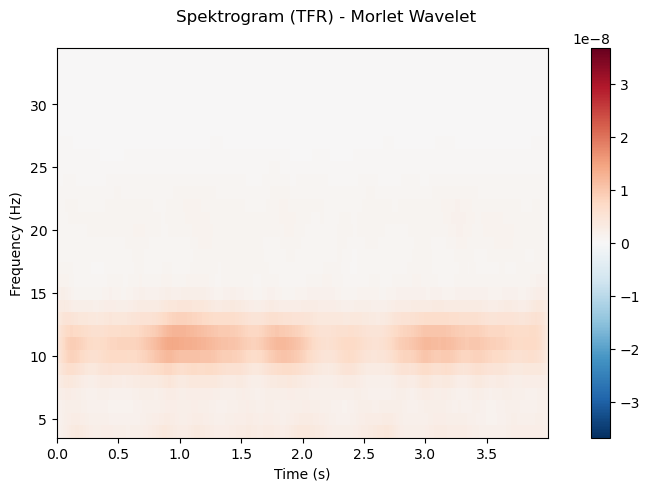

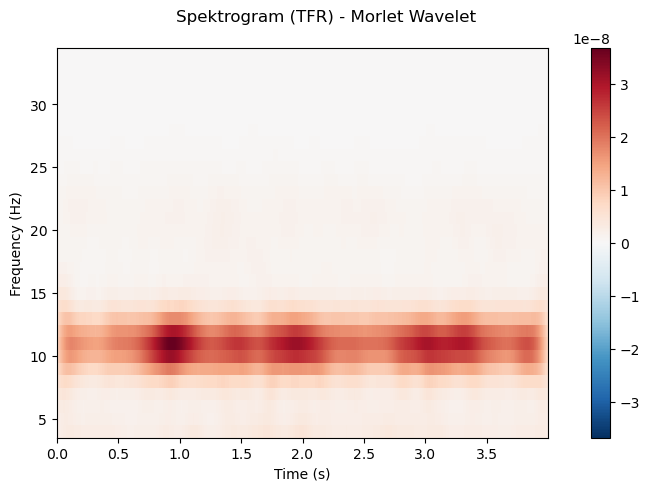

In [12]:
import numpy as np

# Podział sygnału na epoki
epochs = mne.make_fixed_length_epochs(raw_sample, duration=4.0, preload=True)

# Definicja częstotliwości i liczby cykli Morleta
freqs = np.arange(4, 35, 1)
n_cycles = freqs / 2.0

# Obliczenie reprezentacji czaso-częstotliwościowej
tfr = mne.time_frequency.tfr_morlet(
    epochs, 
    freqs=freqs, 
    n_cycles=n_cycles, 
    return_itc=False, 
    average=True
)

# Wykres dla wybranych kanałów centralnych i potylicznych
tfr.plot(picks=['Fz', 'Cz', 'Pz', 'O1', 'O2'], title="Spektrogram (TFR) - Morlet Wavelet")
plt.show()

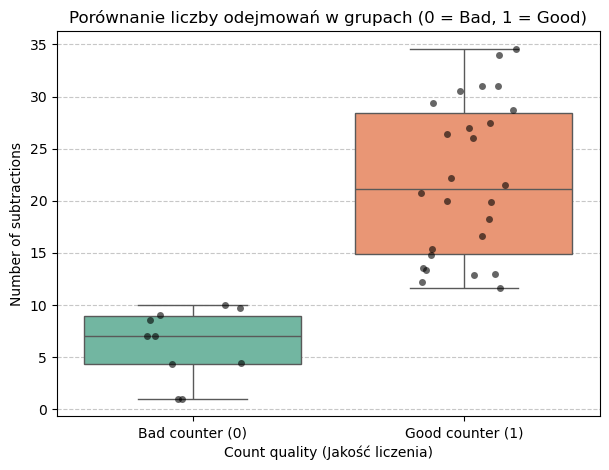

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

# Wykres pudełkowy z nałożonymi punktami (strip plot)
sns.boxplot(
    data=info,
    x="Count quality",
    y="Number of subtractions",
    hue="Count quality",
    palette="Set2",
    legend=False,
)
sns.stripplot(
    data=info,
    x="Count quality",
    y="Number of subtractions",
    color="black",
    alpha=0.6,
    jitter=0.2,
)

plt.title("Porównanie liczby odejmowań w grupach (0 = Bad, 1 = Good)")
plt.xlabel("Count quality (Jakość liczenia)")
plt.ylabel("Number of subtractions")
plt.xticks([0, 1], ["Bad counter (0)", "Good counter (1)"])
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

<Figure size 600x500 with 0 Axes>

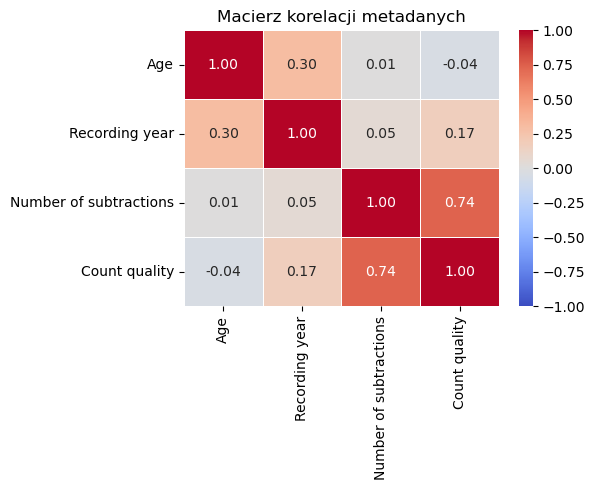

In [19]:
plt.figure(figsize=(6, 5))

# Wybór kolumn numerycznych z metadanych
numeric_cols = info[
    ["Age", "Recording year", "Number of subtractions", "Count quality"]
]
corr_matrix = numeric_cols.corr()

# Rysowanie mapy ciepła
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)

plt.title("Macierz korelacji metadanych")
plt.tight_layout()
plt.show()

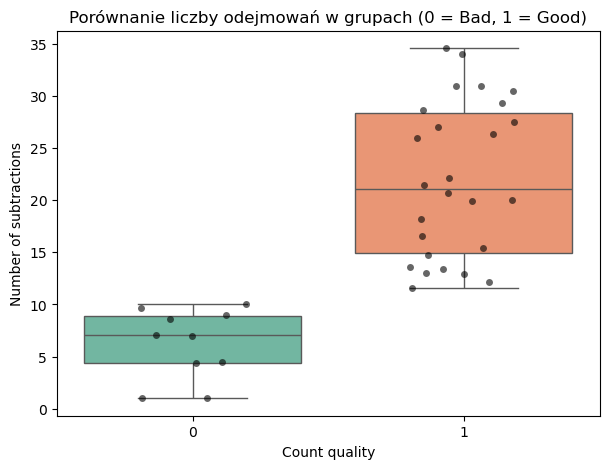

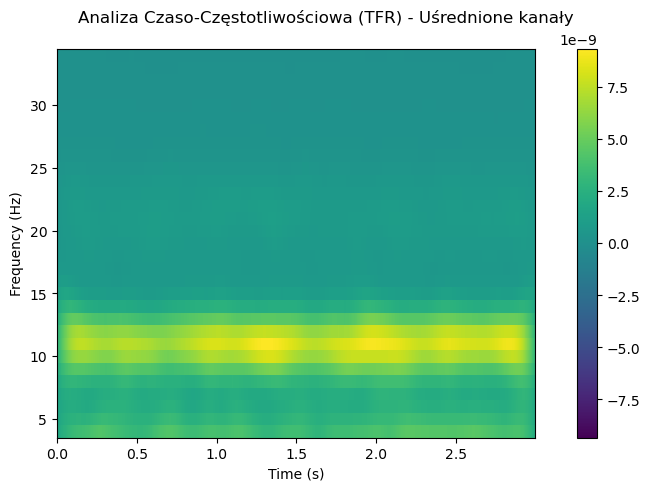

In [14]:
import mne
import numpy as np
import matplotlib.pyplot as plt

# 1. Podział ciągłego sygnału na epoki (np. okna 3-sekundowe)
epochs = mne.make_fixed_length_epochs(raw_sample, duration=3.0, preload=True)

# 2. Określenie zakresu częstotliwości (np. 4 - 35 Hz)
freqs = np.arange(4, 35, 1.0)

# Liczba cykli falki: im wyższa, tym lepsza rozdzielczość częstotliwościowa,
# ale gorsza rozdzielczość czasowa. Często stosuje się n_cycles = freqs / 2.0
n_cycles = freqs / 2.0

# 3. Obliczenie TFR
tfr = mne.time_frequency.tfr_morlet(
    epochs, 
    freqs=freqs, 
    n_cycles=n_cycles, 
    use_fft=True, 
    return_itc=False,  # False = interesuje nas moc (power), nie spójność fazowa (ITC)
    average=True       # Uśrednienie wyników po wszystkich epokach
)

# 4. Rysowanie TFR dla wybranych kanałów
fig = tfr.plot(
    picks=['Fz', 'Cz', 'P3', 'P4', 'O1'], 
    combine='mean',          # Uśrednij wykres dla wybranych kanałów
    title='Analiza Czaso-Częstotliwościowa (TFR) - Uśrednione kanały',
    cmap='viridis'
)
plt.show()

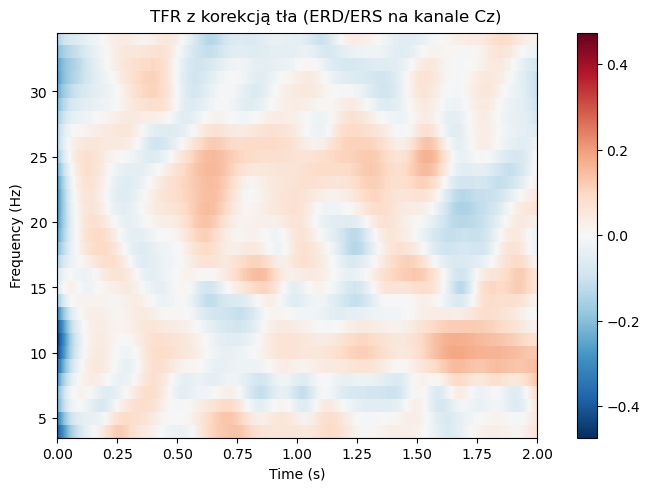

In [20]:
# baseline=(t_min, t_max) - przedział czasu przyjęty jako punkt odniesienia
tfr.plot(
    picks=['Cz'],
    baseline=(0.0, 0.5),    # Okres referencyjny od 0.0 do 0.5 sekundy epoki
    mode='logratio',        # Zmiana logarytmiczna: 10 * log10(signal / baseline) [w dB]
    tmin=-2, tmax=2,        # Skala kolorów
    title='TFR z korekcją tła (ERD/ERS na kanale Cz)'
)
plt.show()

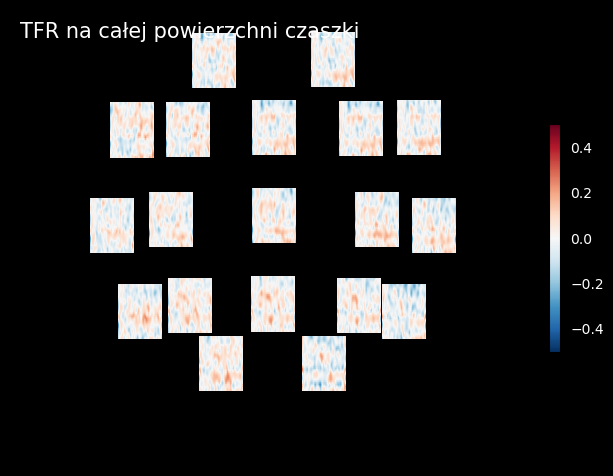

In [16]:
# Wykres TFR ułożony w układzie elektrod na głowie
tfr.plot_topo(
    baseline=(0.0, 0.5), 
    mode='logratio', 
    title='TFR na całej powierzchni czaszki'
)
plt.show()

=== STATYSTYKI OPISOWE I WERYFIKACJA HIPOTEZ ===
Liczebność: Grupa B = 10, Grupa G = 26
Liczba odejmowań: B = 6.22 ± 3.37 | G = 21.99 ± 7.46
  -> Test t Welcha: t = 8.7200, p = 4.6059e-10
  -> Test Mann-Whitney: U = 260.0, p = 4.7772e-06
Wiek: B = 18.40 ± 2.01 | G = 18.19 ± 2.26
  -> Test t: t = -0.2678, p = 0.7918 (brak różnic istotnych)
Płeć: Chi2 = 0.0000, p = 1.0000 (brak różnic istotnych)



/tmp/ipykernel_679885/3660713998.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=info, x="Quality_label", y="Number of subtractions", ax=axes[0, 0],


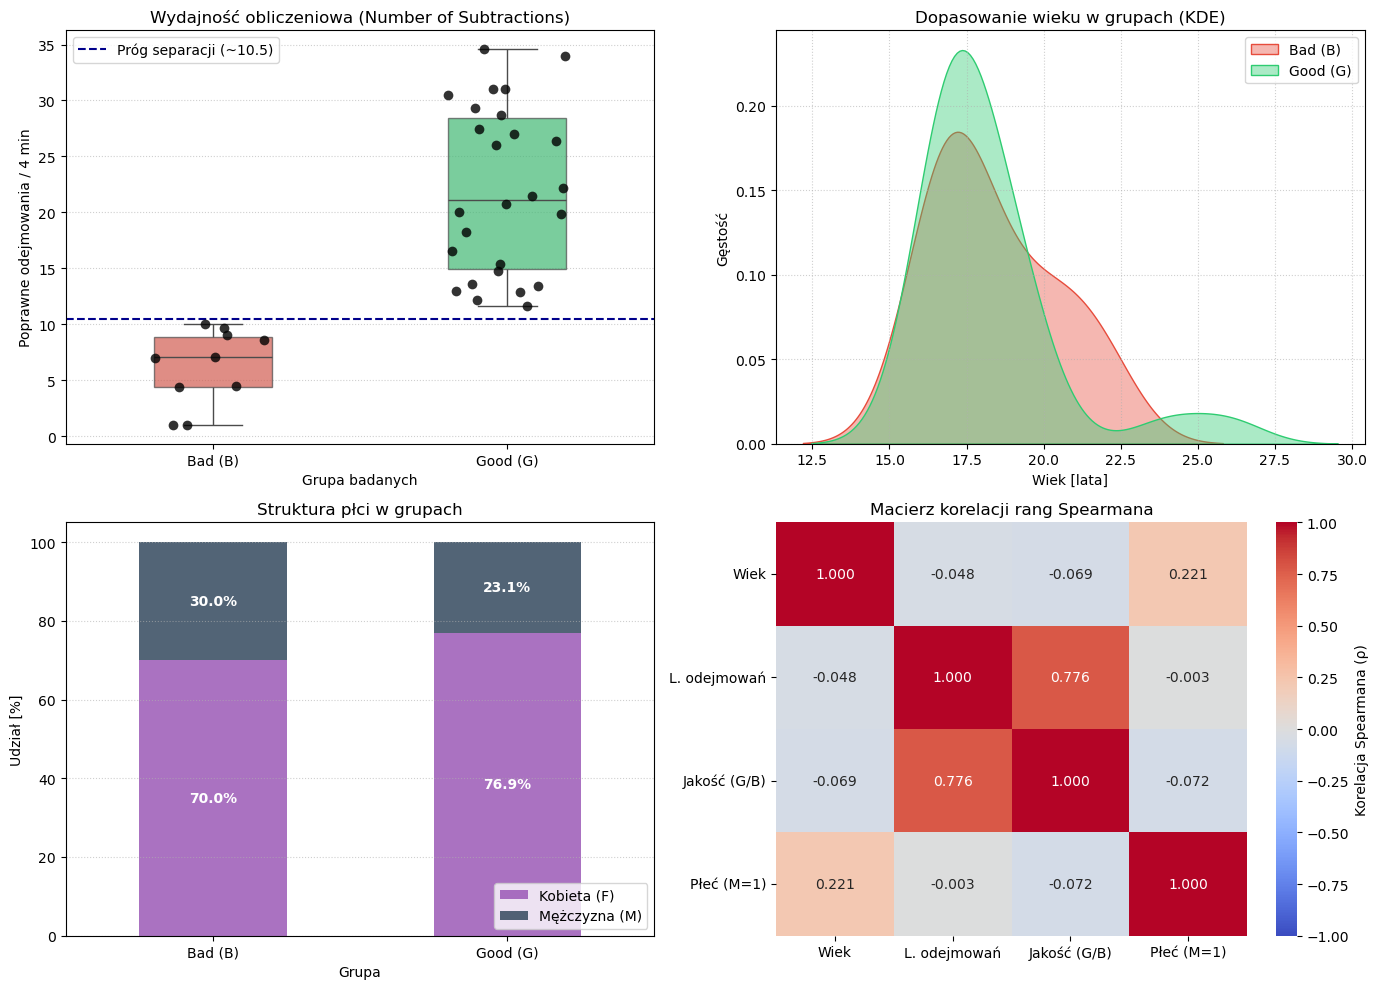

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Wczytanie i przygotowanie metadanych
info = pd.read_csv(DATA_DIR / "subject-info.csv")

# Standaryzacja etykiety tekstowej i kodowania
info["Quality_label"] = info["Count quality"].map({0: "Bad (B)", 1: "Good (G)"})
info["Gender_code"] = info["Gender"].map({"F": 0, "M": 1})

# 2. Testy statystyczne hipotez badawczych
g_sub = info[info["Count quality"] == 1]["Number of subtractions"]
b_sub = info[info["Count quality"] == 0]["Number of subtractions"]

g_age = info[info["Count quality"] == 1]["Age"]
b_age = info[info["Count quality"] == 0]["Age"]

# Test normalności rozkładu Shapiro-Wilka
shapiro_sub_g = stats.shapiro(g_sub)
shapiro_sub_b = stats.shapiro(b_sub)

# Test istotności różnic liczby odejmowań (Welch t-test + nieparametryczny Mann-Whitney U)
t_sub, p_sub = stats.ttest_ind(g_sub, b_sub, equal_var=False)
u_sub, p_u_sub = stats.mannwhitneyu(g_sub, b_sub)

# Test różnicy wieku (sprawdzenie homogeniczności grup)
t_age, p_age = stats.ttest_ind(g_age, b_age, equal_var=False)
u_age, p_u_age = stats.mannwhitneyu(g_age, b_age)

# Test niezależności chi-kwadrat dla płci
chi2_gender, p_gender, _, _ = stats.chi2_contingency(pd.crosstab(info["Count quality"], info["Gender"]))

print("=== STATYSTYKI OPISOWE I WERYFIKACJA HIPOTEZ ===")
print(f"Liczebność: Grupa B = {len(b_sub)}, Grupa G = {len(g_sub)}")
print(f"Liczba odejmowań: B = {b_sub.mean():.2f} ± {b_sub.std():.2f} | G = {g_sub.mean():.2f} ± {g_sub.std():.2f}")
print(f"  -> Test t Welcha: t = {t_sub:.4f}, p = {p_sub:.4e}")
print(f"  -> Test Mann-Whitney: U = {u_sub}, p = {p_u_sub:.4e}")
print(f"Wiek: B = {b_age.mean():.2f} ± {b_age.std():.2f} | G = {g_age.mean():.2f} ± {g_age.std():.2f}")
print(f"  -> Test t: t = {t_age:.4f}, p = {p_age:.4f} (brak różnic istotnych)")
print(f"Płeć: Chi2 = {chi2_gender:.4f}, p = {p_gender:.4f} (brak różnic istotnych)\n")

# 3. Wizualizacja 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# [0,0] Boxplot + stripplot wydajności
sns.boxplot(data=info, x="Quality_label", y="Number of subtractions", ax=axes[0, 0],
            palette=["#e74c3c", "#2ecc71"], width=0.4, boxprops=dict(alpha=0.7))
sns.stripplot(data=info, x="Quality_label", y="Number of subtractions", ax=axes[0, 0],
              color="black", jitter=0.2, size=7, alpha=0.8)
axes[0, 0].axhline(y=10.5, color="darkblue", linestyle="--", label="Próg separacji (~10.5)")
axes[0, 0].set_title("Wydajność obliczeniowa (Number of Subtractions)")
axes[0, 0].set_ylabel("Poprawne odejmowania / 4 min")
axes[0, 0].set_xlabel("Grupa badanych")
axes[0, 0].legend(loc="upper left")
axes[0, 0].grid(axis="y", linestyle=":", alpha=0.6)

# [0,1] Rozkład gęstości wieku (KDE)
sns.kdeplot(data=info[info["Count quality"] == 0], x="Age", ax=axes[0, 1],
            label="Bad (B)", fill=True, color="#e74c3c", alpha=0.4)
sns.kdeplot(data=info[info["Count quality"] == 1], x="Age", ax=axes[0, 1],
            label="Good (G)", fill=True, color="#2ecc71", alpha=0.4)
axes[0, 1].set_title("Dopasowanie wieku w grupach (KDE)")
axes[0, 1].set_xlabel("Wiek [lata]")
axes[0, 1].set_ylabel("Gęstość")
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle=":", alpha=0.6)

# [1,0] Udział płci w grupach
ct = pd.crosstab(info["Quality_label"], info["Gender"], normalize="index") * 100
ct.plot(kind="bar", stacked=True, ax=axes[1, 0], color=["#9b59b6", "#34495e"], alpha=0.85, rot=0)
axes[1, 0].set_title("Struktura płci w grupach")
axes[1, 0].set_ylabel("Udział [%]")
axes[1, 0].set_xlabel("Grupa")
axes[1, 0].legend(["Kobieta (F)", "Mężczyzna (M)"], loc="lower right")
for c in axes[1, 0].containers:
    axes[1, 0].bar_label(c, fmt="%.1f%%", label_type="center", color="white", fontweight="bold")
axes[1, 0].grid(axis="y", linestyle=":", alpha=0.6)

# [1,1] Heatmapa korelacji rang Spearmana
corr_cols = ["Age", "Number of subtractions", "Count quality", "Gender_code"]
corr_labels = ["Wiek", "L. odejmowań", "Jakość (G/B)", "Płeć (M=1)"]
corr_matrix = info[corr_cols].corr(method="spearman").values

sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1, 1],
            xticklabels=corr_labels, yticklabels=corr_labels, cbar_kws={"label": "Korelacja Spearmana (ρ)"})
axes[1, 1].set_title("Macierz korelacji rang Spearmana")

plt.tight_layout()
plt.show()

In [22]:
import mne
import numpy as np

OLD2NEW = {"T3": "T7", "T4": "T8", "T5": "P7", "T6": "P8"}

def preprocess_eeg_raw(raw_input):
    """
    Rygorystyczny preprocessing:
    - Usunięcie A1-A2 i ECG
    - Montaż standard_1020
    - Re-referencja CAR (Common Average Reference)
    - Filtr pasmowo-zaporowy (Notch 50 Hz)
    - Filtr pasmowoprzepustowy (FIR 0.5 - 45 Hz)
    """
    raw = raw_input.copy().load_data()
    
    # Czyszczenie nazw kanałów
    raw.rename_channels({ch: ch.replace("EEG ", "").strip() for ch in raw.ch_names})
    
    # Odrzucamy elektrody uszne oraz EKG z kanałów skalpowych
    drop_chs = [ch for ch in raw.ch_names if ("A1" in ch.upper() or "A2" in ch.upper() or "ECG" in ch.upper())]
    if drop_chs:
        raw.drop_channels(drop_chs)
        
    # Standard 10-20
    raw.rename_channels({ch: OLD2NEW[ch] for ch in raw.ch_names if ch in OLD2NEW})
    raw.set_montage("standard_1020", match_case=False, on_missing="warn")
    
    # 1. Filtracja zaporowa 50 Hz (interferencja sieciowa)
    raw.notch_filter(freqs=np.array([50.0]), method="fir", verbose=False)
    
    # 2. Filtr pasmowoprzepustowy 0.5 - 45 Hz
    raw.filter(l_freq=0.5, h_freq=45.0, fir_design="firwin", verbose=False)
    
    # 3. Re-referencjonowanie do średniej (CAR)
    raw.set_eeg_reference(ref_channels="average", projection=False, verbose=False)
    
    return raw


def create_clean_epochs(raw, epoch_len=4.0, reject_p2p=120e-6):
    """
    Dzieli sygnał na równe epoki i odrzuca te z artefaktami amplitudowymi > reject_p2p.
    """
    reject_criteria = dict(eeg=reject_p2p) if reject_p2p is not None else None
    
    epochs = mne.make_fixed_length_epochs(
        raw, 
        duration=epoch_len, 
        overlap=0.0, 
        preload=True, 
        verbose=False
    )
    
    # Automatyczny drop epok o amplitudzie przekraczającej próg (np. 120 uV)
    if reject_criteria:
        epochs.drop_bad(reject=reject_criteria, verbose=False)
        
    return epochs

In [23]:
def compute_epoch_features(epochs):
    """
    Ekstrakcja:
    - Względnych mocy pasmowych (Delta, Theta, Alpha, Beta, Gamma)
    - Cognitive Load Index (Theta_frontal / Alpha_parietal)
    - Frontal Alpha Asymmetry: ln(Alpha_F4) - ln(Alpha_F3)
    """
    bands = {
        "delta": (1.0, 4.0),
        "theta": (4.0, 8.0),
        "alpha": (8.0, 12.0),
        "beta": (13.0, 30.0),
        "gamma": (30.0, 45.0)
    }
    
    ch_names = epochs.ch_names
    psd_obj = epochs.compute_psd(method="welch", fmin=1.0, fmax=45.0, n_fft=int(epochs.info["sfreq"] * 2), verbose=False)
    psds, freqs = psd_obj.get_data(return_freqs=True)  # (n_epochs, n_channels, n_freqs)
    
    total_power = psds.sum(axis=-1, keepdims=True) + 1e-12
    
    # 1. Względna moc pasmowa
    band_rel_powers = []
    feature_names = []
    
    band_power_dict = {}
    for b_name, (fmin, fmax) in bands.items():
        idx_band = np.logical_and(freqs >= fmin, freqs <= fmax)
        # Suma w paśmie / moc całkowita
        rel_power = psds[:, :, idx_band].sum(axis=-1) / total_power.squeeze(-1)
        band_rel_powers.append(rel_power)
        band_power_dict[b_name] = rel_power
        
        for ch in ch_names:
            feature_names.append(f"{ch}_{b_name}")
            
    # Łączenie cech pasmowych: (n_epochs, n_channels * 5)
    X_bands = np.concatenate(band_rel_powers, axis=1)
    
    # 2. Wskaźniki kognitywne
    # Indeksy kanałów
    fz_idx = [i for i, ch in enumerate(ch_names) if ch in ["Fz", "F3", "F4"]]
    pz_idx = [i for i, ch in enumerate(ch_names) if ch in ["Pz", "P3", "P4"]]
    
    # Theta frontal / Alpha parietal (Task Load Index)
    theta_frontal = band_power_dict["theta"][:, fz_idx].mean(axis=-1, keepdims=True)
    alpha_parietal = band_power_dict["alpha"][:, pz_idx].mean(axis=-1, keepdims=True) + 1e-12
    task_load = theta_frontal / alpha_parietal
    
    # Frontal Alpha Asymmetry: ln(Alpha_F4) - ln(Alpha_F3)
    f3_idx = ch_names.index("F3") if "F3" in ch_names else None
    f4_idx = ch_names.index("F4") if "F4" in ch_names else None
    
    if f3_idx is not None and f4_idx is not None:
        alpha_f3 = band_power_dict["alpha"][:, [f3_idx]] + 1e-12
        alpha_f4 = band_power_dict["alpha"][:, [f4_idx]] + 1e-12
        faa = np.log(alpha_f4) - np.log(alpha_f3)
    else:
        faa = np.zeros((len(epochs), 1))
        
    X_all = np.concatenate([X_bands, task_load, faa], axis=1)
    feature_names.extend(["CLI_ThetaF_AlphaP", "FAA_F4_F3"])
    
    return X_all, feature_names


def build_full_dataset(records, metadata_df, epoch_len=4.0, reject_p2p=120e-6):
    """
    Przetwarza wszystkie nagrania i łączy je w spójny DataFrame z metadanymi podmiotów.
    """
    X_list, y_state_list, subj_list = [], [], []
    feature_names = None
    
    print("Rozpoczynanie przetwarzania wszystkich plików EDF...")
    for (subj_id, state), raw_edf in sorted(records.items()):
        raw_clean = preprocess_eeg_raw(raw_edf)
        epochs = create_clean_epochs(raw_clean, epoch_len=epoch_len, reject_p2p=reject_p2p)
        
        if len(epochs) == 0:
            print(f"Ostrzeżenie: Subject{subj_id:02d}_{state} - brak czystych epok po odrzuceniu.")
            continue
            
        feats, feat_names = compute_epoch_features(epochs)
        if feature_names is None:
            feature_names = feat_names
            
        X_list.append(feats)
        y_state_list.append(np.full(len(feats), 0 if state == 1 else 1)) # 0: spoczynek, 1: zadanie
        subj_list.append(np.full(len(feats), subj_id))
        
    X = np.concatenate(X_list, axis=0)
    y_state = np.concatenate(y_state_list, axis=0)
    subjects = np.concatenate(subj_list, axis=0)
    
    # Tworzenie kompletnego DataFrame
    df_features = pd.DataFrame(X, columns=feature_names)
    df_features["state"] = y_state
    df_features["subject_id"] = subjects
    
    # Mapowanie metadanych (Good/Bad, Number of subtractions)
    sub_map = metadata_df.set_index("Subject")
    
    # Dodanie prefixu SubjectXX
    df_features["Subject_str"] = df_features["subject_id"].apply(lambda s: f"Subject{s:02d}")
    df_features["count_quality"] = df_features["Subject_str"].map(sub_map["Count quality"])
    df_features["n_subtractions"] = df_features["Subject_str"].map(sub_map["Number of subtractions"])
    df_features["gender"] = df_features["Subject_str"].map(sub_map["Gender"])
    df_features["age"] = df_features["Subject_str"].map(sub_map["Age"])
    
    return df_features, feature_names

# Uruchomienie budowania zbioru cech
df_dataset, feat_cols = build_full_dataset(records, info, epoch_len=4.0, reject_p2p=120e-6)
print(f"\nWygenerowano zbiór: {df_dataset.shape[0]} epok, {len(feat_cols)} wyekstrahowanych cech EEG.")
print(f"Liczba epok w stanie spoczynku: {(df_dataset['state'] == 0).sum()}")
print(f"Liczba epok w stanie zadania: {(df_dataset['state'] == 1).sum()}")

Rozpoczynanie przetwarzania wszystkich plików EDF...

Wygenerowano zbiór: 2019 epok, 97 wyekstrahowanych cech EEG.
Liczba epok w stanie spoczynku: 1510
Liczba epok w stanie zadania: 509


In [24]:
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score

# ==============================================================================
# ZADANIE 1: Stan Spoczynku (0) vs Stan Zadania (1) - Klasyfikacja Epok
# ==============================================================================
print("="*65)
print("ZADANIE 1: KLASYFIKACJA STANU (Spoczynek vs Zadanie) - GroupKFold")
print("="*65)

X_task1 = df_dataset[feat_cols].values
y_task1 = df_dataset["state"].values
groups_task1 = df_dataset["subject_id"].values

gkf = GroupKFold(n_splits=5)
rf_clf = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))

acc_scores_t1 = []
auc_scores_t1 = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_task1, y_task1, groups_task1)):
    X_train, X_val = X_task1[train_idx], X_task1[val_idx]
    y_train, y_val = y_task1[train_idx], y_task1[val_idx]
    
    rf_clf.fit(X_train, y_train)
    y_pred = rf_clf.predict(X_val)
    y_proba = rf_clf.predict_proba(X_val)[:, 1]
    
    acc = accuracy_score(y_val, y_pred)
    auc = roc_auc_score(y_val, y_proba)
    acc_scores_t1.append(acc)
    auc_scores_t1.append(auc)
    print(f"Fold {fold + 1}: Accuracy = {acc:.4f}, ROC-AUC = {auc:.4f}")

print(f"\n[ZADANIE 1] Średnia Dokładność (Accuracy): {np.mean(acc_scores_t1):.4f} ± {np.std(acc_scores_t1):.4f}")
print(f"[ZADANIE 1] Średnie ROC-AUC:             {np.mean(auc_scores_t1):.4f} ± {np.std(auc_scores_t1):.4f}")

# ==============================================================================
# ZADANIE 2: Good (G=1) vs Bad (B=0) Counters - Klasyfikacja na Poziomie Podmiotów
# ==============================================================================
print("\n" + "="*65)
print("ZADANIE 2: KLASYFIKACJA CECHY (Good vs Bad Counters) - Per-Subject")
print("="*65)

# Agregujemy średnią wartość cech w stanie zadania (state == 1) dla każdego badanego
df_task_only = df_dataset[df_dataset["state"] == 1]
subject_features = df_task_only.groupby("Subject_str")[feat_cols].mean()
subject_targets = df_task_only.groupby("Subject_str")["count_quality"].first()

X_task2 = subject_features.values
y_task2 = subject_targets.values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
gb_clf = make_pipeline(StandardScaler(), GradientBoostingClassifier(n_estimators=50, random_state=42))

acc_scores_t2 = []
auc_scores_t2 = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_task2, y_task2)):
    X_train, X_val = X_task2[train_idx], X_task2[val_idx]
    y_train, y_val = y_task2[train_idx], y_task2[val_idx]
    
    gb_clf.fit(X_train, y_train)
    y_pred = gb_clf.predict(X_val)
    y_proba = gb_clf.predict_proba(X_val)[:, 1]
    
    acc_scores_t2.append(accuracy_score(y_val, y_pred))
    auc_scores_t2.append(roc_auc_score(y_val, y_proba))

print(f"\n[ZADANIE 2] Średnia Dokładność (Accuracy): {np.mean(acc_scores_t2):.4f} ± {np.std(acc_scores_t2):.4f}")
print(f"[ZADANIE 2] Średnie ROC-AUC:             {np.mean(auc_scores_t2):.4f} ± {np.std(auc_scores_t2):.4f}")

ZADANIE 1: KLASYFIKACJA STANU (Spoczynek vs Zadanie) - GroupKFold
Fold 1: Accuracy = 0.6914, ROC-AUC = 0.6764
Fold 2: Accuracy = 0.7632, ROC-AUC = 0.8055
Fold 3: Accuracy = 0.7708, ROC-AUC = 0.6817
Fold 4: Accuracy = 0.7582, ROC-AUC = 0.6777
Fold 5: Accuracy = 0.6398, ROC-AUC = 0.5613

[ZADANIE 1] Średnia Dokładność (Accuracy): 0.7247 ± 0.0511
[ZADANIE 1] Średnie ROC-AUC:             0.6805 ± 0.0773

ZADANIE 2: KLASYFIKACJA CECHY (Good vs Bad Counters) - Per-Subject

[ZADANIE 2] Średnia Dokładność (Accuracy): 0.7536 ± 0.0906
[ZADANIE 2] Średnie ROC-AUC:             0.7167 ± 0.2552


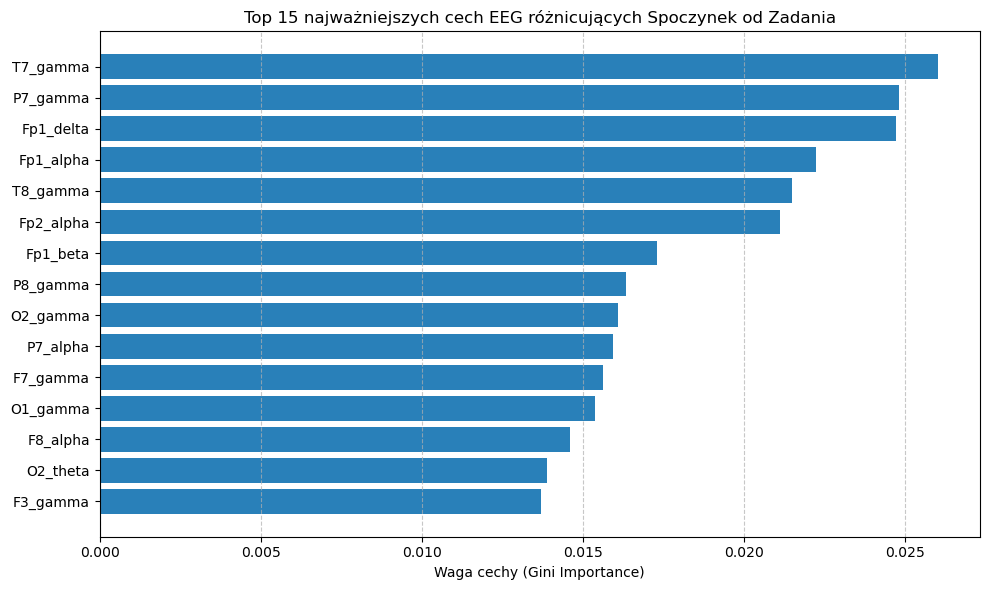

In [25]:
import matplotlib.pyplot as plt

# Dopasowanie modelu do analizy wag cech
rf_full = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
rf_full.fit(X_task1, y_task1)

importances = rf_full.feature_importances_
top_indices = np.argsort(importances)[::-1][:15]

plt.figure(figsize=(10, 6))
plt.barh(range(15), importances[top_indices][::-1], color="#2980b9", align="center")
plt.yticks(range(15), [feat_cols[i] for i in top_indices][::-1])
plt.xlabel("Waga cechy (Gini Importance)")
plt.title("Top 15 najważniejszych cech EEG różnicujących Spoczynek od Zadania")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()